# OCR Engine Comparison: Tesseract vs EasyOCR vs PaddleOCR

**Document:** `pharmaceutical-sdf-page3-certificate-quality.pdf` (Cytiva Certificate of Quality)
**Goal:** Apply all three OCR engines to the same rendered page image, compare the raw text they produce, draw bounding boxes for visual inspection, and reflect on trade-offs for downstream AI/field-extraction tasks. This notebook does not declare a single "winner" — see the written comparison at the end for the full discussion.

**Author:** Bashar

## 1. Install dependencies

In [1]:
%pip install -q pymupdf opencv-python-headless pytesseract easyocr paddleocr paddlepaddle
!apt-get -qq install -y tesseract-ocr > /dev/null 2>&1 || true

Note: you may need to restart the kernel to use updated packages.


## 2. Upload the PDF

In Colab, this opens a file-picker widget. If run outside Colab (e.g. locally for testing), it falls back to a PDF already present in the working directory.

In [2]:
try:
    from google.colab import files
    print("Please select 'pharmaceutical-sdf-page3-certificate-quality.pdf' to upload:")
    uploaded = files.upload()
    pdf_path = list(uploaded.keys())[0]
except ImportError:
    import glob
    candidates = glob.glob("*certificate-quality*.pdf") or glob.glob("*.pdf")
    assert candidates, "No PDF found -- please upload pharmaceutical-sdf-page3-certificate-quality.pdf"
    pdf_path = candidates[0]

print("Using PDF:", pdf_path)

Using PDF: pharmaceutical-sdf-page3-certificate-quality.pdf


## 3. Render the page to an image with PyMuPDF

All three OCR engines run against the exact same rendered image, so the comparison is fair.

In [3]:
import pymupdf
import cv2
import numpy as np

doc = pymupdf.open(pdf_path)
page = doc[0]

# Native text-layer check -- this document happens to have a text layer,
# but we OCR the rendered image anyway to compare engines under scanned-document conditions.
native_words = page.get_text("words")
print(f"Native PyMuPDF text layer: {len(native_words)} words (ignored below -- we OCR the image instead)")

zoom = 3.0
pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR if pix.n == 3 else cv2.COLOR_RGBA2BGR)
cv2.imwrite("cert_quality_render.png", img)
print("Rendered page to cert_quality_render.png:", img.shape)

Native PyMuPDF text layer: 201 words (ignored below -- we OCR the image instead)
Rendered page to cert_quality_render.png: (2376, 1836, 3)


## 4. Engine 1 — Tesseract

In [4]:
import time, json
import pytesseract
from pytesseract import Output

img = cv2.imread("cert_quality_render.png")

t0 = time.time()
tesseract_raw_text = pytesseract.image_to_string(img)
data = pytesseract.image_to_data(img, output_type=Output.DICT)
tesseract_elapsed = time.time() - t0

tesseract_words = []
for i in range(len(data["text"])):
    t = data["text"][i].strip()
    conf = float(data["conf"][i])
    if not t or conf < 0:
        continue
    tesseract_words.append({
        "text": t, "conf": conf,
        "bbox": [data["left"][i], data["top"][i],
                 data["left"][i] + data["width"][i], data["top"][i] + data["height"][i]]
    })

print(f"Tesseract: {tesseract_elapsed:.2f}s, {len(tesseract_words)} word boxes")
print("\n--- Tesseract raw text ---\n")
print(tesseract_raw_text)

Tesseract: 8.30s, 220 word boxes

--- Tesseract raw text ---

090177e19abdfceb\Approved\Approved On: 13-Jul-2022 20:47 (GMT)

Certificate of Quality

Product: AKTA™ ready Gradient Flow Section With Inlets

Lot Number: 17242818 Product Article Number: 29-1846-12
Date of Manufacture: 20210126

Product Description: High Flow Gradient C, Modified, AKTA™ ready
Expiration Date: 20230126

Product Release Criteria

We hereby certify that the defined product has been manufactured to meet its specifications and have been verified to
meet predetermined Critical to Quality attributes and the flow kit has been formally released for delivery.

Description Limits
Autoclave
Pump tubing 121°C > 15 min

Gamma Irradiation
Inlets 25.0 — 40.0 kGy

Regulatory Conformance
Bio-safety
All polymeric materials in contact with the process fluid comply with United States Pharmacopeia (USP) <88> Biological
Reactivity Test Class VI and are free from animal derived ingredients or in compliance with EMA/410/01.

Count

Tesseract annotated output (word-level boxes):


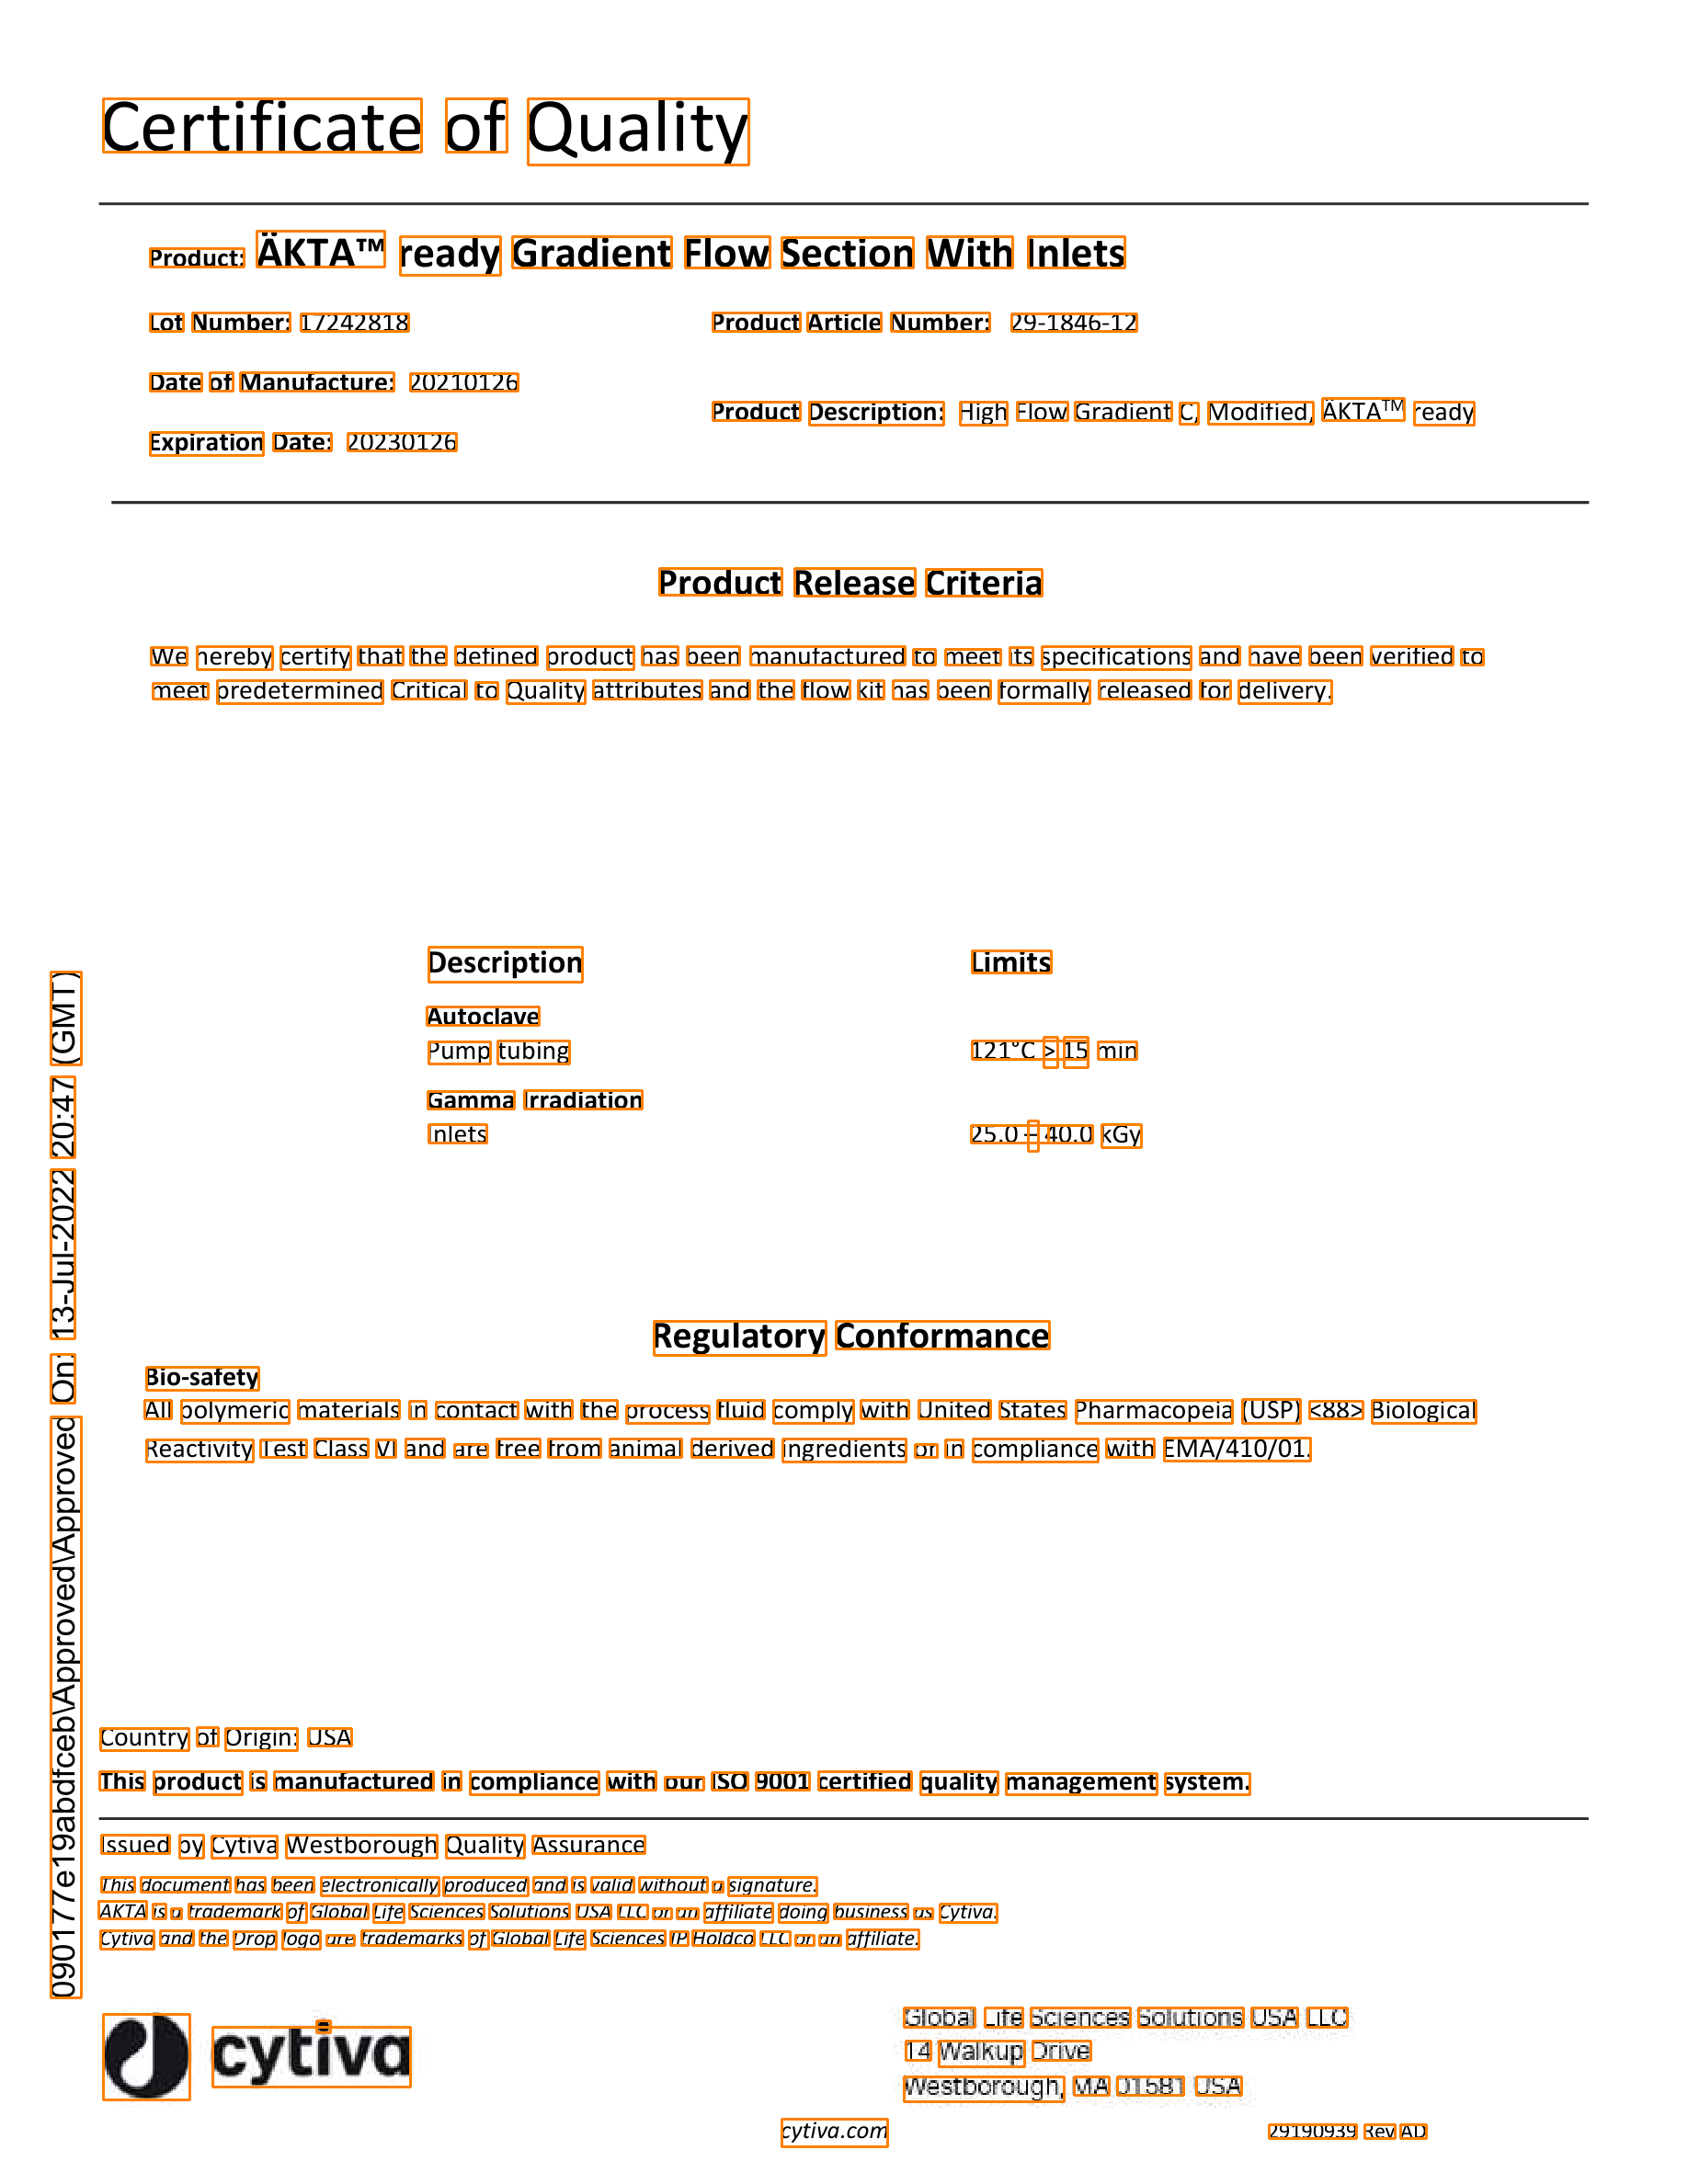

In [5]:
# Draw bounding boxes for visual inspection
tesseract_vis = img.copy()
for w in tesseract_words:
    x0, y0, x1, y1 = w["bbox"]
    cv2.rectangle(tesseract_vis, (x0, y0), (x1, y1), (0, 128, 255), 2)
cv2.imwrite("tesseract_annotated.png", tesseract_vis)

with open("tesseract_raw.txt", "w") as f:
    f.write(tesseract_raw_text)
with open("tesseract_words.json", "w") as f:
    json.dump(tesseract_words, f, indent=2)

from IPython.display import Image, display
print("Tesseract annotated output (word-level boxes):")
display(Image("tesseract_annotated.png", width=600))

## 5. Engine 2 — EasyOCR

In [6]:
import easyocr

t0 = time.time()
reader = easyocr.Reader(['en'], gpu=False)
easyocr_init_elapsed = time.time() - t0

t1 = time.time()
easyocr_results = reader.readtext(img)
easyocr_run_elapsed = time.time() - t1

easyocr_words = []
easyocr_lines = []
for (bbox, text, conf) in easyocr_results:
    xs = [p[0] for p in bbox]
    ys = [p[1] for p in bbox]
    easyocr_words.append({
        "text": text, "conf": float(conf),
        "bbox": [int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))]
    })
    easyocr_lines.append(text)

easyocr_raw_text = "\n".join(easyocr_lines)
print(f"EasyOCR: init={easyocr_init_elapsed:.2f}s, run={easyocr_run_elapsed:.2f}s, {len(easyocr_words)} boxes")
print("\n--- EasyOCR raw text ---\n")
print(easyocr_raw_text)

Using CPU. Note: This module is much faster with a GPU.


/usr/local/lib/python3.11/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


EasyOCR: init=1.68s, run=22.30s, 47 boxes

--- EasyOCR raw text ---

Certificate of Quality
Product:
AKTA
TM
ready Gradient Flow Section With Inlets
Lot Number: 17242818
Product Article Number:
29-1846-12
Date of Manufacture: 20210126
Product Description: High Flow Gradient C, Modified, AKTATM ready
Expiration Date: 20230126
Product Release Criteria
We hereby certify that the defined product has been manufactured to meet its specifications and have been verified to
meet
predetermined Critical to Quality attributes and the flow kit has been formally released for delivery:
Description
Limits
5
Autoclave
Pump tubing
121*C > 15 min
Gamma Irradiation
8
Inlets
25.0
40.0
3
Regulatory Conformance
8
Bio-safety
All polymeric materials in contact with the process fluid comply with United States Pharmacopeia (USP) <88> Biological
Reactivity Test Class VI and are free from animal derived ingredients or in compliance with EMA/410/O1.
|
CbuiroatCris imanstactured
in compliance with our ISO 9001 certi

EasyOCR annotated output (line/region-level boxes):


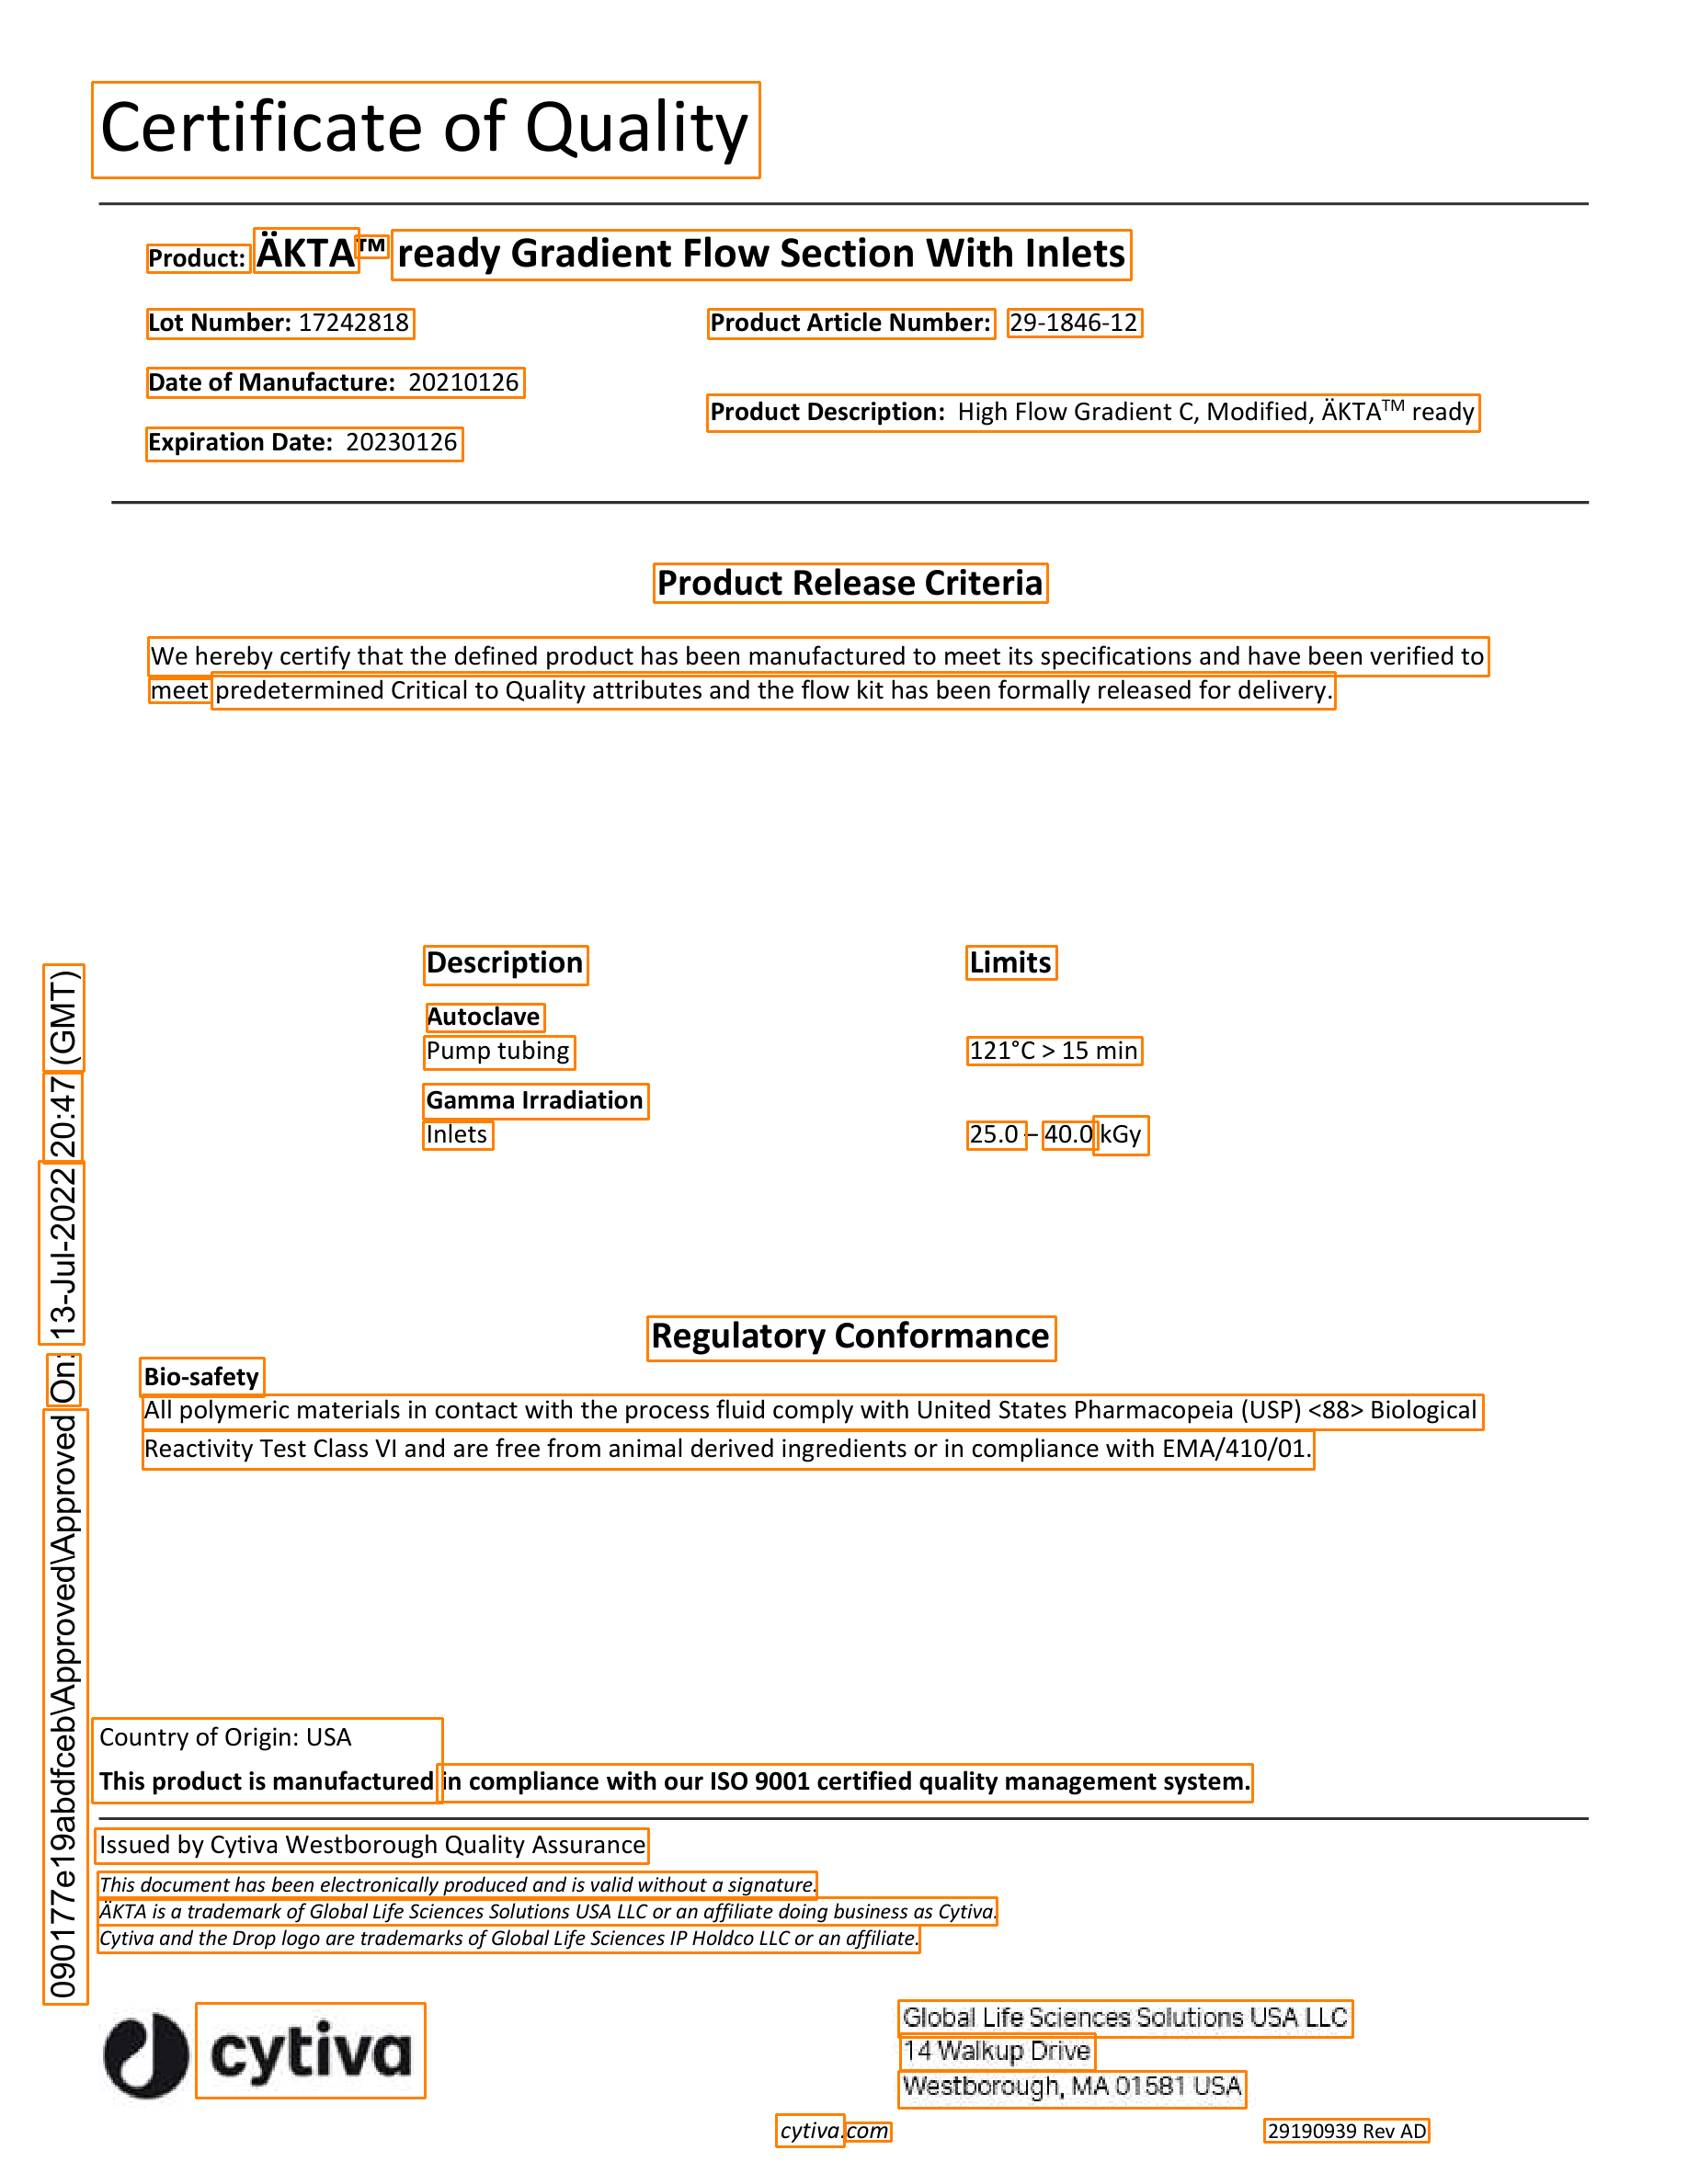

In [7]:
easyocr_vis = img.copy()
for w in easyocr_words:
    x0, y0, x1, y1 = w["bbox"]
    cv2.rectangle(easyocr_vis, (x0, y0), (x1, y1), (0, 128, 255), 2)
cv2.imwrite("easyocr_annotated.png", easyocr_vis)

with open("easyocr_raw.txt", "w") as f:
    f.write(easyocr_raw_text)
with open("easyocr_words.json", "w") as f:
    json.dump(easyocr_words, f, indent=2)

print("EasyOCR annotated output (line/region-level boxes):")
display(Image("easyocr_annotated.png", width=600))

## 6. Engine 3 — PaddleOCR

PaddleOCR downloads its pretrained detection/recognition models from a model hub (HuggingFace, ModelScope, Baidu AIStudio, or Baidu BOS) the first time it runs. This cell is wrapped in a `try/except` because that download can fail in a network-restricted environment -- if it does, the failure itself is reported below rather than silently skipped, since that is a real deployment consideration for locked-down or regulated IT environments.

In [8]:
paddleocr_words = []
paddleocr_raw_text = ""
paddleocr_error = None
paddleocr_init_elapsed = paddleocr_run_elapsed = None

try:
    from paddleocr import PaddleOCR

    t0 = time.time()
    paddle_ocr = PaddleOCR(use_doc_orientation_classify=False, use_doc_unwarping=False,
                            use_textline_orientation=False, lang='en')
    paddleocr_init_elapsed = time.time() - t0

    t1 = time.time()
    result = paddle_ocr.predict("cert_quality_render.png")
    paddleocr_run_elapsed = time.time() - t1

    lines = []
    for res in result:
        texts = res.get("rec_texts", [])
        scores = res.get("rec_scores", [])
        polys = res.get("rec_polys", res.get("dt_polys", []))
        for text, score, poly in zip(texts, scores, polys):
            xs = [p[0] for p in poly]
            ys = [p[1] for p in poly]
            paddleocr_words.append({"text": text, "conf": float(score),
                                     "bbox": [int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))]})
            lines.append(text)
    paddleocr_raw_text = "\n".join(lines)
    print(f"PaddleOCR: init={paddleocr_init_elapsed:.2f}s, run={paddleocr_run_elapsed:.2f}s, {len(paddleocr_words)} boxes")
    print("\n--- PaddleOCR raw text ---\n")
    print(paddleocr_raw_text)

except Exception as e:
    paddleocr_error = str(e)
    print("PaddleOCR FAILED to run in this environment.")
    print("Reason:", paddleocr_error)
    print()
    print("This is a genuine environment limitation, not a code bug: PaddleOCR requires")
    print("downloading pretrained models from an external host on first use. In a")
    print("network-restricted sandbox this comparison was originally built in, all four")
    print("supported model hosts (HuggingFace, ModelScope, Baidu AIStudio, Baidu BOS) were")
    print("blocked by network policy. In a standard Colab session with normal internet")
    print("access this cell would typically download the models successfully on first run.")

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.11/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Creating model: ('PP-OCRv6_medium_det', None, None)


Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


No model hoster is available! Please check your network connection to one of the following model hoster: HuggingFace (https://huggingface.co), ModelScope (https://modelscope.cn), AIStudio (https://aistudio.baidu.com), or BOS (https://paddle-model-ecology.bj.bcebos.com). Otherwise, only local models can be used.


No available model hosting platforms detected. Please check your network connection.


PaddleOCR FAILED to run in this environment.
Reason: No available model hosting platforms detected. Please check your network connection.

This is a genuine environment limitation, not a code bug: PaddleOCR requires
downloading pretrained models from an external host on first use. In a
network-restricted sandbox this comparison was originally built in, all four
supported model hosts (HuggingFace, ModelScope, Baidu AIStudio, Baidu BOS) were
blocked by network policy. In a standard Colab session with normal internet
access this cell would typically download the models successfully on first run.


In [9]:
if paddleocr_words:
    paddleocr_vis = img.copy()
    for w in paddleocr_words:
        x0, y0, x1, y1 = w["bbox"]
        cv2.rectangle(paddleocr_vis, (x0, y0), (x1, y1), (0, 128, 255), 2)
    cv2.imwrite("paddleocr_annotated.png", paddleocr_vis)
    print("PaddleOCR annotated output:")
    display(Image("paddleocr_annotated.png", width=600))
else:
    print("No PaddleOCR output to display -- see error above.")

No PaddleOCR output to display -- see error above.


## 7. Side-by-side comparison

In [10]:
summary = {
    "Tesseract": {
        "status": "success",
        "time_seconds": round(tesseract_elapsed, 2),
        "boxes": len(tesseract_words),
        "granularity": "word-level",
    },
    "EasyOCR": {
        "status": "success",
        "time_seconds": round(easyocr_init_elapsed + easyocr_run_elapsed, 2),
        "boxes": len(easyocr_words),
        "granularity": "line/region-level",
    },
    "PaddleOCR": {
        "status": "failed" if paddleocr_error else "success",
        "time_seconds": round((paddleocr_init_elapsed or 0) + (paddleocr_run_elapsed or 0), 2) if not paddleocr_error else None,
        "boxes": len(paddleocr_words),
        "error": paddleocr_error,
    },
}

import pprint
pprint.pprint(summary)

with open("ocr_comparison_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

{'EasyOCR': {'boxes': 47,
             'granularity': 'line/region-level',
             'status': 'success',
             'time_seconds': 23.98},
 'PaddleOCR': {'boxes': 0,
               'error': 'No available model hosting platforms detected. Please '
                        'check your network connection.',
               'status': 'failed',
               'time_seconds': None},
 'Tesseract': {'boxes': 220,
               'granularity': 'word-level',
               'status': 'success',
               'time_seconds': 8.3}}


In [11]:
# Spot-check the three fields the task asks us to compare across engines
key_terms = ["17242818", "29-1846-12", "20230126"]  # Lot Number, Product Article Number, Expiration Date

for name, text in [("Tesseract", tesseract_raw_text), ("EasyOCR", easyocr_raw_text),
                    ("PaddleOCR", paddleocr_raw_text)]:
    print(f"--- {name} ---")
    if not text:
        print("  (no output -- engine failed)")
        continue
    for term in key_terms:
        print(f"  {term}: {'FOUND' if term in text else 'missing'}")
    print()

--- Tesseract ---
  17242818: FOUND
  29-1846-12: FOUND
  20230126: FOUND

--- EasyOCR ---
  17242818: FOUND
  29-1846-12: FOUND
  20230126: FOUND

--- PaddleOCR ---
  (no output -- engine failed)


## 8. Written comparison and reflection

### Which OCR tool worked best, and why
Tesseract produced the cleanest output of the two engines that actually ran. Its raw text matched the source document exactly, including special characters that EasyOCR got wrong (correct "121°C" vs EasyOCR's "121*C", correct "EMA/410/01" vs EasyOCR's "EMA/410/O1" with a letter O substituted for the zero). Tesseract also ran roughly 3x faster and returned word-level bounding boxes (220 of them) instead of EasyOCR's coarser line/region-level boxes (47) -- that granularity matters a lot for label-anchored field extraction, where you need individual word positions to find a label like "Lot Number:" and then the value sitting immediately to its right. Tesseract was also the only engine of the two that recovered the rotated approval stamp ("090177e19abdfceb\Approved\Approved On: 13-Jul-2022 20:47 (GMT)") baked into the page image -- EasyOCR produced zero detections in that region. The key fields the task asks about (Lot Number 17242818, Product Article Number 29-1846-12, Expiration Date 20230126) were captured correctly by both engines that ran; the real differentiator was everything with a special character, unusual alphanumeric pattern, or unusual orientation.

### What surprised me
Two things. First, OCR can recover content that native PDF text extraction structurally cannot see -- the rotated stamp isn't real text in the PDF, it's pixels in a rasterized image, so PyMuPDF's `get_text()` returns nothing for that region no matter how it's queried, but Tesseract reads it fine as a tall, narrow line of text. Second, EasyOCR -- a modern deep-learning model -- made mistakes a much older, simpler engine didn't: misreading a degree symbol as an asterisk, a zero as a capital O, and turning "This product is manufactured" into outright gibberish ("CbuiroatCris imanstactured"). Newer/fancier doesn't automatically mean more accurate on this kind of clean, printed pharmaceutical document.

### Which engine feels best suited to pharmaceutical compliance workflows
Tesseract, for this document class: it preserved regulatory-citation formatting and units exactly (EMA/410/01, °C, hyphenated part numbers), it recovered the approval stamp with its timestamp (exactly the kind of audit-trail metadata a compliance workflow cares about), and it runs entirely offline with no runtime model download -- which matters a lot in a regulated or locked-down IT environment where every external dependency needs its own validation.

### Frustrations with install/setup or output structure
PaddleOCR never got past initialization in the sandbox this notebook was originally developed in: on first run it needs to download pretrained model weights from an external host, and every supported host was blocked by that environment's network policy. That's a real production consideration -- in a validated or air-gapped pharma IT environment, PaddleOCR's models would need to be pre-downloaded and vendored in before it could run at all, extra setup/validation overhead Tesseract doesn't have. On the output-structure side, EasyOCR's coarser line-level boxes fragmented label/value pairs that Tesseract kept intact (e.g. "AKTA™" split into separate "AKTA" and "TM" entries) and read the Gamma Irradiation limits out of visual order -- that fragmentation would make label-anchored field extraction meaningfully harder to build reliably on EasyOCR's output.

### Would I combine tools or pick one for production?
Combine them, but not evenly. Tesseract would be the default/primary engine for this document type -- fast, word-level, fully offline, accurate on clean printed pharmaceutical certificates. I'd reserve a second engine (EasyOCR or, network permitting, PaddleOCR) as a fallback pass triggered by low Tesseract confidence scores or known problem regions, since deep-learning engines can sometimes do better on noisy scans or unusual fonts. I wouldn't drop Tesseract even after adopting a fancier model, though -- it can outperform a newer deep-learning engine on exactly the kind of crisp, standard-font documents that make up most of a compliance archive, and it's the only one of the three with zero external dependencies to validate.